# `panorama.tex` — Demo

Worked examples of the **`tex`** module of PANORAMA: bibliography checks of LaTeX manuscripts, VizieR and SIMBAD queries for lists of targets, and pickled figures that can be reopened and edited.

* **Examples 1-3** — bibliography checks of a mock LaTeX manuscript: uncited, missing and duplicated entries, with BibTeX and biblatex citations (with and without the refsection argument), `@string`, `@comment` and `@preamble` blocks (ignored), case-sensitive citation keys, DOIs written with and without the `https://doi.org/` prefix, in braces or in quotes, and the `\nocite{*}` wildcard (warning of `nobib`, ignored by `missingbib`).
* **Examples 4-6** — catalog queries for a small sample of OB stars: VizieR from a Python list (Hipparcos) and from a text file (Gaia DR3; comments, empty lines and extra columns ignored, and an unknown object kept as a row of `nan`), and SIMBAD with and without output file (an unknown object kept with empty values), with a first estimate of the color excess.
* **Examples 7-9** — saving, reopening and re-editing pickled figures (shown inline), and the special cases of `savefig_pkl` (single format string, known extension removed, other suffixes kept in the base name, `pkl` rejected).

**Files:** input files are written to `data_and_results/tex/data/` and outputs to `data_and_results/tex/results/` (relative to `Demos/`, the folder of this notebook).

**Internet:** examples 4-6 require internet access; without it they print `Skipped: ...` and the rest of the notebook still runs.

Run the cells in order (*Run All*).

## Imports

Python packages (figures shown inline) and PANORAMA functions.

In [1]:
%matplotlib inline
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import warnings

from panorama import (
                      dupbib,  # BIB
                      missingbib,  # BIB
                      nobib,  # BIB
                      querysimbad,  # QUERY
                      queryviz,  # QUERY
                      read_pkl,  # MATPLOTLIB
                      savefig_pkl,  # MATPLOTLIB
                     )

	PANORAMA v1.2.1 loaded...
		- To see the available functions, run:
			panorama.functions()          # Lists all functions, grouped by submodule
			panorama.functions('obs')     # Lists the functions of a single submodule
		- To see the docstring of a specific function (e.g. 'visibility'), run:
			help(panorama.visibility)
		- To silence this message, set the environment variable PANORAMA_QUIET=1



## Setup

Working directories and a mock LaTeX manuscript (.aux and .bib files).

In [2]:
work_dir_data    = Path("./data_and_results/tex/data/")
work_dir_results = Path("./data_and_results/tex/results/")
work_dir_data.mkdir(parents=True, exist_ok=True)
work_dir_results.mkdir(parents=True, exist_ok=True)

aux_file        = work_dir_data / "paper.aux"
aux_file_nocite = work_dir_data / "paper_nocite.aux"
bib_file        = work_dir_data / "references.bib"


# BibTeX citations, biblatex citations with and without the refsection argument,
# a key absent from the .bib file (Edlen1966) and a case variant of 'Sana2012'
aux_file.write_text(
                    r"""
\citation{Herrero1992,Langer2014}
\citation{Repolust2004}
\abx@aux@cite{0}{Lamers1995}
\abx@aux@cite{Puls2008}
\citation{Edlen1966}
\citation{sana2012}
""",
                    encoding="utf-8"
                   )

aux_file_nocite.write_text(
                           r"""
\citation{Herrero1992}
\citation{*}
""",
                           encoding="utf-8"
                          )

# Non-entry blocks, a key repeated in another case and two papers stored under two keys each
bib_file.write_text(
                    r"""
@string{aap = "A\&A"}
@comment{Mock bibliography for the PANORAMA tex demo}
@preamble{"\providecommand{\noopsort}[1]{}"}

@article{Herrero1992,  title={Demo entry 1}, journal=aap, doi={10.0000/demo.0001}}
@article{Langer2014,   title={Demo entry 2}, journal=aap, doi={10.0000/demo.0002}}
@article{Repolust2004, title={Demo entry 3}, journal=aap}
@article{Lamers1995,   title={Demo entry 4 (biblatex citation)}, journal={ApJ}}
@article{Puls2008,     title={Demo entry 5 (biblatex citation without refsection)}, journal={A\&ARv}}
@article{Sana2012,     title={Demo entry 6 (cited as 'sana2012')}, journal={Science}}
@article{langer2014,   title={Duplicated key (case variant of Langer2014)}, journal=aap}
@article{LK2014,       title={Same paper as Langer2014 under another key}, journal=aap, doi={https://doi.org/10.0000/DEMO.0002}}
@article{Herrero1992b, title={Same paper as Herrero1992, DOI in quotes}, journal=aap, doi = "10.0000/DEMO.0001"}
""",
                    encoding="utf-8"
                   )


print(f"Mock manuscript written to {work_dir_data}: {aux_file.name}, {aux_file_nocite.name}, {bib_file.name}")

Mock manuscript written to data_and_results/tex/data: paper.aux, paper_nocite.aux, references.bib


## Example 1: Bibliography entries never cited in the manuscript

Uncited bibliography entries, and the \nocite{*} warning.

In [3]:
unused_keys = nobib(aux_file, bib_file)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    unused_keys_nocite = nobib(aux_file_nocite, bib_file)


print(f"\n.aux file: {aux_file.name}")
print(f".bib file: {bib_file.name}")
print(f"\tUncited keys = {unused_keys}")
print("\t(@string, @comment and @preamble blocks are ignored; BibTeX and biblatex citations are both read)")
print("\t('Sana2012' is cited as 'sana2012' and 'langer2014' is never cited: keys are case-sensitive)")

print(f"\n.aux file with \\nocite{{*}}: {aux_file_nocite.name}")
print(f"\tUncited keys = {unused_keys_nocite}")
for w in caught:
    print(f"\tWarning: {w.message}")


.aux file: paper.aux
.bib file: references.bib
	Uncited keys = ['Herrero1992b', 'LK2014', 'Sana2012', 'langer2014']
	(@string, @comment and @preamble blocks are ignored; BibTeX and biblatex citations are both read)
	('Sana2012' is cited as 'sana2012' and 'langer2014' is never cited: keys are case-sensitive)

.aux file with \nocite{*}: paper_nocite.aux
	Uncited keys = ['Herrero1992b', 'LK2014', 'Lamers1995', 'Langer2014', 'Puls2008', 'Repolust2004', 'Sana2012', 'langer2014']


## Example 2: Citations without a .bib entry ('?' in the PDF)

Cited keys missing from the .bib file, and the \nocite{*} wildcard.

In [4]:
missing_keys        = missingbib(aux_file, bib_file)
missing_keys_nocite = missingbib(aux_file_nocite, bib_file)


print(f"\n.aux file: {aux_file.name}")
print(f"\tMissing keys = {missing_keys}")
print("\t('sana2012' does not match the .bib key 'Sana2012': keys are compared case-sensitively, as LaTeX does)")

print(f"\n.aux file with \\nocite{{*}}: {aux_file_nocite.name}")
print(f"\tMissing keys = {missing_keys_nocite}")
print("\t(The \\nocite{*} wildcard is not a key and is ignored without warning)")


.aux file: paper.aux
	Missing keys = ['Edlen1966', 'sana2012']
	('sana2012' does not match the .bib key 'Sana2012': keys are compared case-sensitively, as LaTeX does)

.aux file with \nocite{*}: paper_nocite.aux
	Missing keys = []
	(The \nocite{*} wildcard is not a key and is ignored without warning)


## Example 3: Duplicated .bib entries

Duplicated entries (by key and by DOI).

In [5]:
duplicates = dupbib(bib_file)


print("\nKeys defined more than once (case-insensitive, first spelling reported):")
for key, n in duplicates['keys'].items():
    print(f"\t{key:<15} x{n}")

print("\nDOIs shared by several keys:")
for doi, keys in duplicates['dois'].items():
    print(f"\t{doi:<35} {keys}")
print("\t(DOIs are compared case-insensitively, without the 'https://doi.org/' prefix, in braces or quotes)")


Keys defined more than once (case-insensitive, first spelling reported):
	Langer2014      x2

DOIs shared by several keys:
	10.0000/demo.0001                   ['Herrero1992', 'Herrero1992b']
	10.0000/demo.0002                   ['Langer2014', 'LK2014']
	(DOIs are compared case-insensitively, without the 'https://doi.org/' prefix, in braces or quotes)


## Example 4: VizieR query from a Python list

VizieR query from a Python list (Hipparcos main catalog).

In [6]:
ob_stars        = ["HD 91316", "HD 37042", "HD 149757"]  # Rho Leo, theta2 Ori B, zeta Oph
catalog_hip     = "I/239/hip_main"
output_viz_list = work_dir_results / "hipparcos_list.txt"


print(f"\nCatalog '{catalog_hip}' for {ob_stars}")
caught = []
try:
    print("\n")
    with warnings.catch_warnings(record=True) as caught:  # Failed queries issue a warning and are kept as empty rows
        warnings.simplefilter("always")
        queryviz(
                 input_file=ob_stars,
                 catalog=catalog_hip,
                 output_file=output_viz_list,
                 col_width=15
                )
    header = output_viz_list.read_text(encoding="utf-8").splitlines()[0].split()
    print(f"\tOutput: {output_viz_list} ({len(header) - 1} catalog columns)")
    print(f"\tFirst columns: {header[:6]}")
    print(f"\tLast columns : {header[-6:]}")
except Exception as e:  # No internet access, VizieR unavailable or astroquery missing
    print(f"\tSkipped: {str(e).splitlines()[0]}")
for w in caught:
    print(f"\tWarning: {w.message}")


Catalog 'I/239/hip_main' for ['HD 91316', 'HD 37042', 'HD 149757']




	Skipped: No successful VizieR queries.


## Example 5: VizieR query from a text file

VizieR query from a text file (Gaia DR3), with an unknown object kept as an empty row.

In [7]:
objects_file = work_dir_data / "targets.txt"
objects_file.write_text(
                        "# OB targets (names with spaces written with underscores; only the first column is read)\n"
                        "HD_91316              B1Iab\n"
                        "\n"
                        "NOT_A_REAL_STAR_XYZ\n"
                        "HD_37042              B0.5V\n",
                        encoding="utf-8"
                       )
catalog_gaia    = "I/355/gaiadr3"
output_viz_file = work_dir_results / "gaia_file.txt"


print(f"\nReading targets from: {objects_file.name}")
print("\t(Comment lines, empty lines and the spectral-type column are ignored)")
caught = []
try:
    print("\n")
    with warnings.catch_warnings(record=True) as caught:  # The unknown object issues a warning and is kept as a row of 'nan'
        warnings.simplefilter("always")
        queryviz(
                 input_file=objects_file,
                 catalog=catalog_gaia,
                 output_file=output_viz_file,
                 col_width=30  # Wide columns: 'DR3Name' ('Gaia DR3 <source_id>') has up to 28 characters
                )
    lines = output_viz_file.read_text(encoding="utf-8").splitlines()
    for line in lines:
        print(f"\t{line[:90]}...")  # First three columns: 'Object', '_r' and 'DR3Name'
    print(f"\tOutput: {output_viz_file} ({len(lines[0].split()) - 1} catalog columns)")
    print("\t(Unknown objects are kept as rows of 'nan', preserving the input order)")
except Exception as e:  # No internet access, VizieR unavailable or astroquery missing
    print(f"\tSkipped: {str(e).splitlines()[0]}")
for w in caught:
    print(f"\tWarning: {w.message}")


Reading targets from: targets.txt
	(Comment lines, empty lines and the spectral-type column are ignored)




	Skipped: No successful VizieR queries.


## Example 6: SIMBAD query and color excess of OB stars

SIMBAD query: coordinates, spectral types, color excess and an unknown object.

In [8]:
bv0_ob        = -0.28  # Approximate intrinsic (B - V)_0 of early-B / late-O stars [mag]
output_simbad = work_dir_results / "simbad.txt"


try:
    simbad = querysimbad(
                         input_file=ob_stars,
                         output_file=output_simbad
                        )
    print(f"\n\t{'Object':<10} {'SpT':<14} {'RA':>12} {'Dec':>12} {'V':>6} {'B-V':>6} {'E(B-V)':>7} {'A_V':>6}")
    for name, s in simbad.items():
        ebv = s['B-V'] - bv0_ob  # E(B - V) = (B - V) - (B - V)_0
        print(
              f"\t{name:<10} {s['sp_type']:<14} {s['ra_hms']:>12} {s['dec_dms']:>12} "
              f"{s['V']:6.2f} {s['B-V']:6.2f} {ebv:7.2f} {3.1 * ebv:6.2f}"
             )
    print(f"\n\tOutput: {output_simbad}")
    print("\n")

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        simbad_only = querysimbad(input_file=["HD_91316", "NOT_A_REAL_STAR_XYZ"])  # No output file: results only returned

    print(f"\n\tWithout output file: {list(simbad_only)}")
    print(f"\t\tHD_91316            → parallax {simbad_only['HD_91316']['plx']:.2f} mas")
    print(f"\t\tNOT_A_REAL_STAR_XYZ → main_id = '{simbad_only['NOT_A_REAL_STAR_XYZ']['main_id']}', V = {simbad_only['NOT_A_REAL_STAR_XYZ']['V']}")
    for w in caught:
        if Path(w.filename).name == "tex.py":  # Only the warnings issued by 'querysimbad', not those of astroquery
            print(f"\tWarning: {w.message}")
except Exception as e:  # No internet access, SIMBAD unavailable or astroquery missing
    print(f"\n\tSkipped: {str(e).splitlines()[0]}")


	Skipped: SIMBAD service could not be configured (internet connection required): Unable to access the capabilities endpoint at:


## Example 7: Save a figure (PDF + PNG) and its pickle copy

Save a figure together with its pickle copy.

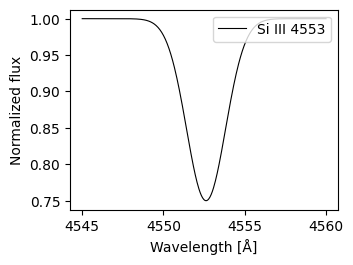


Files written in data_and_results/tex/results:
	SiIII_profile.pdf         14.1 kB
	SiIII_profile.png        107.2 kB
	SiIII_profile.pkl        117.6 kB


In [9]:
wave = np.linspace(4545., 4560., 400)
flux = 1. - 0.25 * np.exp(-0.5 * ((wave - 4552.62) / 1.2)**2)  # Mock Si III 4552.62 profile

fig, ax = plt.subplots(figsize=(3.46, 2.6))  # A&A single-column width
ax.plot(wave, flux, color="k", lw=0.8, label="Si III 4553")
ax.set_xlabel("Wavelength [Å]")
ax.set_ylabel("Normalized flux")
ax.legend(loc="upper right")
display(fig)  # Inline display (the figure is closed by 'savefig_pkl')

written_files = savefig_pkl(fig, work_dir_results / "SiIII_profile", formats=("pdf", "png"))


print(f"\nFiles written in {work_dir_results}:")
for path in written_files:
    print(f"\t{path.name:<22} {path.stat().st_size / 1024:7.1f} kB")

## Example 8: Reopen and edit a pickled figure

Reopen the pickled figure and edit it without recomputing.

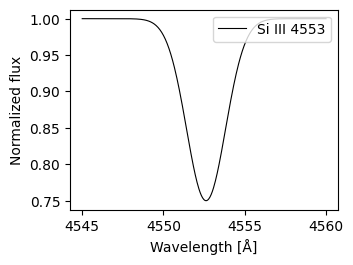

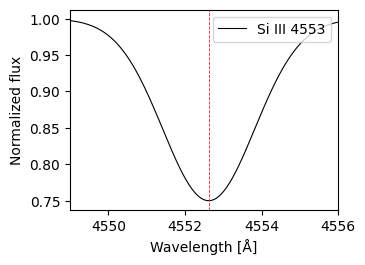


Loaded figure : Figure, size [3.46 2.6 ] in
	x label     : Wavelength [Å]
	New x range : 4549-4556 Å
	Saved as    : ['SiIII_profile_zoom.pdf', 'SiIII_profile_zoom.pkl'] in data_and_results/tex/results


In [10]:
fig_loaded = read_pkl(work_dir_results / "SiIII_profile.pkl", show=True)  # Reopened figure, shown inline
ax_loaded  = fig_loaded.axes[0]
ax_loaded.set_xlim(4549., 4556.)  # E.g. zoom requested by a referee
ax_loaded.axvline(4552.62, color="tab:red", ls="--", lw=0.6)
display(fig_loaded)  # Edited figure

edited_files = savefig_pkl(fig_loaded, work_dir_results / "SiIII_profile_zoom")


print(f"\nLoaded figure : {type(fig_loaded).__name__}, size {fig_loaded.get_size_inches()} in")
print(f"\tx label     : {ax_loaded.get_xlabel()}")
print(f"\tNew x range : {ax_loaded.get_xlim()[0]:.0f}-{ax_loaded.get_xlim()[1]:.0f} Å")
print(f"\tSaved as    : {[p.name for p in edited_files]} in {work_dir_results}")

## Example 9: Special cases of savefig_pkl

Special cases of savefig_pkl: single format string, known extension removed, other suffixes kept, 'pkl' rejected.

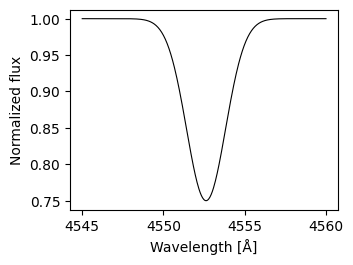


Single format string + '.png' in the filename:
	Saved as : ['SiIII_profile_single.png', 'SiIII_profile_single.pkl']

Suffix that is not a requested format (wavelength in the filename):
	Saved as : ['SiIII_4552.62.pdf', 'SiIII_4552.62.pkl']

'pkl' in formats:
	Rejected: Image formats 'formats' must not include 'pkl' (the pickle copy is always written). Got ['pdf', 'pkl'].


In [11]:
fig_case, ax_case = plt.subplots(figsize=(3.46, 2.6))  # A&A single-column width
ax_case.plot(wave, flux, color="k", lw=0.8)
ax_case.set_xlabel("Wavelength [Å]")
ax_case.set_ylabel("Normalized flux")
display(fig_case)

case_files = savefig_pkl(
                         fig_case,
                         work_dir_results / "SiIII_profile_single.png",  # Known extension: removed from the base name
                         formats="png",  # A single format given as a string
                         close=False
                        )

dotted_files = savefig_pkl(
                           fig_case,
                           work_dir_results / "SiIII_4552.62",  # Suffix '.62' is not a requested format: kept in the base name
                           formats=("pdf",),
                           close=False
                          )


print("\nSingle format string + '.png' in the filename:")
print(f"\tSaved as : {[p.name for p in case_files]}")

print("\nSuffix that is not a requested format (wavelength in the filename):")
print(f"\tSaved as : {[p.name for p in dotted_files]}")

print("\n'pkl' in formats:")
try:
    savefig_pkl(fig_case, work_dir_results / "SiIII_profile_bad", formats=["pdf", "pkl"])
except ValueError as e:  # The pickle copy is always written
    print(f"\tRejected: {e}")

plt.close(fig_case)